# PS-S1: exact, variational, and noisy A/B simulation

This notebook executes the canonical Stage 1 pipeline and then displays its generated records. The governing source is the October 14, 2026 Phase 1 Master Challenge Guide. All architecture/noise results are simulations; no hardware was run. The Hamiltonian is source-confirmed. Magnetization axis and normalization remain undefined in the guide, so project conventions are labeled explicitly.

The optimizer failure is preserved among the nine canonical starts; the restart diagnostic remains separate. The supplementary E4 pattern study is not run by the default pipeline.

In [1]:
from pathlib import Path
import subprocess, sys
ROOT = Path.cwd()
if not (ROOT / "scripts" / "reproduce.py").is_file():
    raise RuntimeError("Execute this notebook from the project root")
subprocess.run([sys.executable, "scripts/reproduce.py"], cwd=ROOT, check=True)
print("Canonical pipeline completed; E4 and manifest regeneration are intentionally separate.")

[run] exact validation


Independent exact checks: dense spin matrix, sparse matrix, Qiskit Pauli matrix, Jordan-Wigner free-fermion spectrum
  g  dense_ground_energy  sparse_ground_energy  qiskit_pauli_ground_energy  free_fermion_ground_energy  max_abs_spectrum_diff_dense_free_fermion  magnetization_x_sum_dense  magnetization_x_sum_free_fermion   ground_state_gap
0.5    -3.42703408890808       -3.427034088908           -3.42703408890808           -3.42703408890808                      3.10862446895044e-15           1.84050560908425                  1.84050560908425 0.0947875877430771
  1    -4.75877048314363       -4.758770483144           -4.75877048314364           -4.75877048314363                      5.32907051820075e-15           3.24038194194737                  3.24038194194737  0.694592710667718
1.5    -6.50389155712641       -6.503891557126           -6.50389155712641           -6.50389155712641                       3.5527136788005e-15            3.6601080883831                  3.66010808838311   

architecture  nodes  edges             degree_sequence  diameter  average_shortest_path_length  noninduced_P4_placements  noninduced_C4_placements  noninduced_K1,3_placements
    A_branch      5      4             [3, 2, 1, 1, 1]         3                      1.800000                         2                         0                           1
     B_ref12      9     12 [5, 4, 3, 3, 2, 2, 2, 2, 1]         4                      1.944444                        47                         3                          16
[run] canonical VQE and A/B compilation


Finished 9 principal VQE starts and 27 ideal result rows.
Actual optimizer classifications:
optimizer_outcome_classification
optimizer_failure_or_iteration_limit           1
optimizer_success_and_project_threshold_met    8
  g  seed  optimizer_success                        optimizer_termination_message  approximation_or_error  relative_energy_error  final_gradient_inf_norm            optimizer_outcome_classification
0.5    42               True CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH            3.237410e-13           9.446683e-14             3.962656e-07 optimizer_success_and_project_threshold_met
0.5     7               True CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH            1.335820e-12           3.897890e-13             1.983833e-07 optimizer_success_and_project_threshold_met
0.5    21               True CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH            2.033929e-13           5.934953e-14             2.425530e-07 optimizer_success_and_project

[run] separate VQE restart diagnostic


...

Noise variant=kit-literal-all-one-qubit-gates; gates=['rz', 'sx', 'x']; records=18; independent seeds=36
                    approximation_or_error  standard_error  magnetization_z_sum
architecture                                                                   
Processor A_branch                0.394043        0.035304            -0.020454
Processor B_ref12                 0.384602        0.035226             0.009983
Saved results/tables/noisy_results.csv and results/raw/noisy_counts.json
[run] pooled, paired, and error-decomposition metrics


Generated AB comparison: per_run=18, summary_by_g_arch=6, paired_difference=4 rows.
  g       architecture  n_runs  optimizer_converged_starts  optimizer_failed_starts  noisy_energy_mean  total_noisy_absolute_error_mean  relative_absolute_error_mean  shot_sem_mean
0.5 Processor A_branch       3                           3                        0        -3.10017904                      0.326855052                  0.0953754891   0.0268557395
0.5  Processor B_ref12       3                           3                        0        -3.12207031                      0.304963776                  0.0889876694   0.0267050467
  1 Processor A_branch       3                           3                        0         -4.3601888                      0.398581681                  0.0837572819   0.0374029726
  1  Processor B_ref12       3                           3                        0        -4.40511068                      0.353659806                  0.0743174749   0.0370011285
1.5 Process

Generated primary figures: A_branch_coupling.png, B_ref12_coupling.png, ideal_ab_resources.png, ideal_vqe_energy_error.png, noisy_ab_energy.png, paired_noisy_energy_difference.png


[run] generated README and report tables


Rendered README.md (188 lines) and report.md from generated tables.
Canonical PS-S1 pipeline completed. E4 was not run; manifest is a frozen release snapshot.
Canonical pipeline completed; E4 and manifest regeneration are intentionally separate.


## Exact references

Independent implementations compare dense/sparse spin matrices, the Qiskit Pauli Hamiltonian, and the free-fermion spectrum. The exact ground state is a post-optimization reference, not the VQE objective.

In [2]:
import pandas as pd
from IPython.display import display
exact = pd.read_csv(ROOT / "results/tables/exact_crosscheck.csv")
display(exact[["g", "dense_ground_energy", "sparse_ground_energy", "qiskit_pauli_ground_energy", "free_fermion_ground_energy", "max_abs_spectrum_diff_dense_free_fermion"]])

,g,dense_ground_energy,sparse_ground_energy,qiskit_pauli_ground_energy,free_fermion_ground_energy,max_abs_spectrum_diff_dense_free_fermion
0,0.5,-3.427034,-3.427034,-3.427034,-3.427034,3.108624e-15
1,1.0,-4.758770,-4.758770,-4.758770,-4.758770,5.329071e-15
2,1.5,-6.503892,-6.503892,-6.503892,-6.503892,3.552714e-15


## Canonical ideal VQE: all nine starts

Initialization seeds are independent starts. `optimizer_success` and the separately derived project energy-tolerance flag are distinct. Do not replace an unsuccessful row with a later restart.

In [3]:
ideal = pd.read_csv(ROOT / "results/tables/ideal_architecture_results.csv")
logical = ideal[ideal.architecture == "ideal logical"].sort_values(["g", "seed"])
display(logical[["g", "seed", "objective_or_accuracy", "classical_reference", "approximation_or_error", "optimizer_success", "optimizer_termination_message", "optimizer_outcome_classification", "meets_project_energy_tolerance"]])

,g,seed,objective_or_accuracy,classical_reference,approximation_or_error,optimizer_success,optimizer_termination_message,optimizer_outcome_classification,meets_project_energy_tolerance
3,0.5,7,-3.427034,-3.427034,1.335820e-12,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,optimizer_success_and_project_threshold_met,True
6,0.5,21,-3.427034,-3.427034,2.033929e-13,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,optimizer_success_and_project_threshold_met,True
0,0.5,42,-3.427034,-3.427034,3.237410e-13,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,optimizer_success_and_project_threshold_met,True
12,1.0,7,-4.758770,-4.758770,2.622258e-11,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,optimizer_success_and_project_threshold_met,True
15,1.0,21,-4.758770,-4.758770,2.374989e-12,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,optimizer_success_and_project_threshold_met,True
9,1.0,42,-4.758770,-4.758770,2.762235e-13,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,optimizer_success_and_project_threshold_met,True
21,1.5,7,-6.503892,-6.503892,1.074696e-13,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,optimizer_success_and_project_threshold_met,True
24,1.5,21,-6.503892,-6.503892,4.066081e-12,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,optimizer_success_and_project_threshold_met,True
18,1.5,42,-6.503590,-6.503892,3.016010e-04,False,STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT,optimizer_failure_or_iteration_limit,False


## Separate restart diagnostic

The diagnostic uses the saved failed-run parameters as a new initialization. It is recorded separately and is not substituted into the canonical table.

In [4]:
restart = pd.read_csv(ROOT / "results/tables/vqe_restart_diagnostic.csv")
display(restart)

,status,source_run_id,g,initial_vqe_seed,initial_parameters_source,original_termination,original_nit,restart_optimizer,restart_success,restart_message,restart_nit,restart_nfev,restart_energy,exact_reference,absolute_error,relative_error,final_gradient_inf_norm,project_threshold,meets_project_threshold
0,SUPPLEMENTAL_RESTART_NOT_A_REPLACEMENT_FOR_BAS...,S1-g1p5-vqe42,1.5,42,saved final parameters from original unsuccess...,STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT,500,L-BFGS-B,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,206,7929,-6.503892,-6.503892,5.888623e-13,9.053999e-14,4.081755e-07,0.000001,True


## Pooled A/B noisy comparison and paired differences

Each energy uses separately sampled Z and X Pauli groups. `shot_sem` is per-run sampling SEM; the paired statistic summarizes between-start matched differences and is reported descriptively, not as a confidence interval.

In [5]:
comparison = pd.read_csv(ROOT / "results/tables/AB_comparison.csv")
display(comparison[comparison.row_type == "summary_by_g_arch"])
display(comparison[comparison.row_type == "paired_difference"])

,row_type,g,seed,architecture,optimizer_success,optimizer_outcome,meets_project_energy_tolerance,ideal_energy,exact_energy,ideal_signed_error,...,relative_absolute_error_sample_sd,relative_absolute_error_sem,shot_sem_mean,shot_sem_sample_sd,shot_sem_sem,n_pairs,mean,sample_sd,sem,difference_definition
18,summary_by_g_arch,0.5,NaN,Processor A_branch,NaN,NaN,NaN,NaN,NaN,NaN,...,0.003591,0.002073,0.026856,0.000188,0.000109,NaN,NaN,NaN,NaN,NaN
19,summary_by_g_arch,0.5,NaN,Processor B_ref12,NaN,NaN,NaN,NaN,NaN,NaN,...,0.004591,0.002651,0.026705,0.000195,0.000112,NaN,NaN,NaN,NaN,NaN
20,summary_by_g_arch,1.0,NaN,Processor A_branch,NaN,NaN,NaN,NaN,NaN,NaN,...,0.003235,0.001868,0.037403,0.000329,0.000190,NaN,NaN,NaN,NaN,NaN
21,summary_by_g_arch,1.0,NaN,Processor B_ref12,NaN,NaN,NaN,NaN,NaN,NaN,...,0.005111,0.002951,0.037001,0.000050,0.000029,NaN,NaN,NaN,NaN,NaN
22,summary_by_g_arch,1.5,NaN,Processor A_branch,NaN,NaN,NaN,NaN,NaN,NaN,...,0.011513,0.006647,0.041652,0.000770,0.000444,NaN,NaN,NaN,NaN,NaN
23,summary_by_g_arch,1.5,NaN,Processor B_ref12,NaN,NaN,NaN,NaN,NaN,NaN,...,0.007903,0.004563,0.041973,0.000508,0.000294,NaN,NaN,NaN,NaN,NaN


,row_type,g,seed,architecture,optimizer_success,optimizer_outcome,meets_project_energy_tolerance,ideal_energy,exact_energy,ideal_signed_error,...,relative_absolute_error_sample_sd,relative_absolute_error_sem,shot_sem_mean,shot_sem_sample_sd,shot_sem_sem,n_pairs,mean,sample_sd,sem,difference_definition
24,paired_difference,0.5,NaN,A_minus_B,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,3.0,0.021891,0.016631,0.009602,sampled A energy minus sampled B energy; match...
25,paired_difference,1.0,NaN,A_minus_B,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,3.0,0.044922,0.011749,0.006783,sampled A energy minus sampled B energy; match...
26,paired_difference,1.5,NaN,A_minus_B,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,3.0,-0.038493,0.073933,0.042685,sampled A energy minus sampled B energy; match...
27,paired_difference,all,NaN,A_minus_B,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,9.0,0.009440,0.053498,0.017833,sampled A energy minus sampled B energy; match...


## Error decomposition and graph descriptors

Signed sampled-minus-exact energy error is separated into its ZZ and X contributions. The closure residual checks numerical consistency. Graph motif counts describe topology, not performance.

In [6]:
display(pd.read_csv(ROOT / "results/tables/noisy_error_decomposition.csv"))
display(pd.read_csv(ROOT / "results/tables/graph_descriptors.csv"))

,g,seed,architecture,exact_zz_energy,sampled_zz_energy,zz_error_contribution,exact_x_energy,sampled_x_energy,x_error_contribution,decomposed_total_error,observed_total_error,closure_residual,shot_sem_z,shot_sem_x,shot_sem_total
0,0.5,42,Processor A_branch,-2.506781,-2.285156,0.221625,-0.920253,-0.828125,0.092128,0.313753,0.313753,2.664535e-15,0.020515,0.017017,0.026654
1,0.5,42,Processor B_ref12,-2.506781,-2.270996,0.235785,-0.920253,-0.863037,0.057216,0.293001,0.293001,2.664535e-15,0.020561,0.017012,0.026687
2,0.5,7,Processor A_branch,-2.506781,-2.254883,0.251898,-0.920253,-0.843506,0.076747,0.328645,0.328645,2.664535e-15,0.021001,0.017009,0.027025
3,0.5,7,Processor B_ref12,-2.506781,-2.271973,0.234809,-0.920253,-0.832275,0.087977,0.322786,0.322786,2.664535e-15,0.020720,0.017168,0.026908
4,0.5,21,Processor A_branch,-2.506781,-2.260742,0.246039,-0.920253,-0.828125,0.092128,0.338167,0.338167,2.664535e-15,0.020721,0.017135,0.026888
5,0.5,21,Processor B_ref12,-2.506781,-2.260254,0.246527,-0.920253,-0.867676,0.052577,0.299104,0.299104,2.664535e-15,0.020409,0.016935,0.026520
6,1.0,42,Processor A_branch,-1.518389,-1.389648,0.128740,-3.240382,-2.969727,0.270655,0.399395,0.399395,1.498801e-15,0.025359,0.027133,0.037138
7,1.0,42,Processor B_ref12,-1.518389,-1.391113,0.127275,-3.240382,-3.001953,0.238429,0.365704,0.365704,1.498801e-15,0.025452,0.026899,0.037031
8,1.0,7,Processor A_branch,-1.518389,-1.356934,0.161455,-3.240382,-2.988281,0.252101,0.413556,0.413556,1.498801e-15,0.026328,0.027084,0.037771
9,1.0,7,Processor B_ref12,-1.518389,-1.383789,0.134599,-3.240382,-3.005371,0.235011,0.369610,0.369610,1.498801e-15,0.025455,0.026774,0.036944


,architecture,name,nodes,edges,degree_sequence,degree_histogram,average_degree,density,connected,component_sizes,diameter,average_shortest_path_length,average_clustering,is_tree,noninduced_P4_placements,noninduced_C4_placements,"noninduced_K1,3_placements",edge_list
0,A_branch,Processor A_branch,5,4,"[3, 2, 1, 1, 1]","{'1': 3, '2': 1, '3': 1}",1.600000,0.400000,True,[5],3,1.800000,0.000000,True,2,0,1,"[[0,1],[1,2],[1,3],[3,4]]"
1,B_ref12,Processor B_ref12,9,12,"[5, 4, 3, 3, 2, 2, 2, 2, 1]","{'1': 1, '2': 4, '3': 2, '4': 1, '5': 1}",2.666667,0.333333,True,[9],4,1.944444,0.133333,False,47,3,16,"[[0,1],[1,2],[1,6],[2,3],[2,6],[2,5],[3,4],[4,..."


## Figures

The noisy-energy bars show ±1 shot SEM, not a confidence interval. The matched-seed scatter is descriptive. Circuit-resource and topology plots are generated from saved tables/configuration.

A_branch_coupling.png


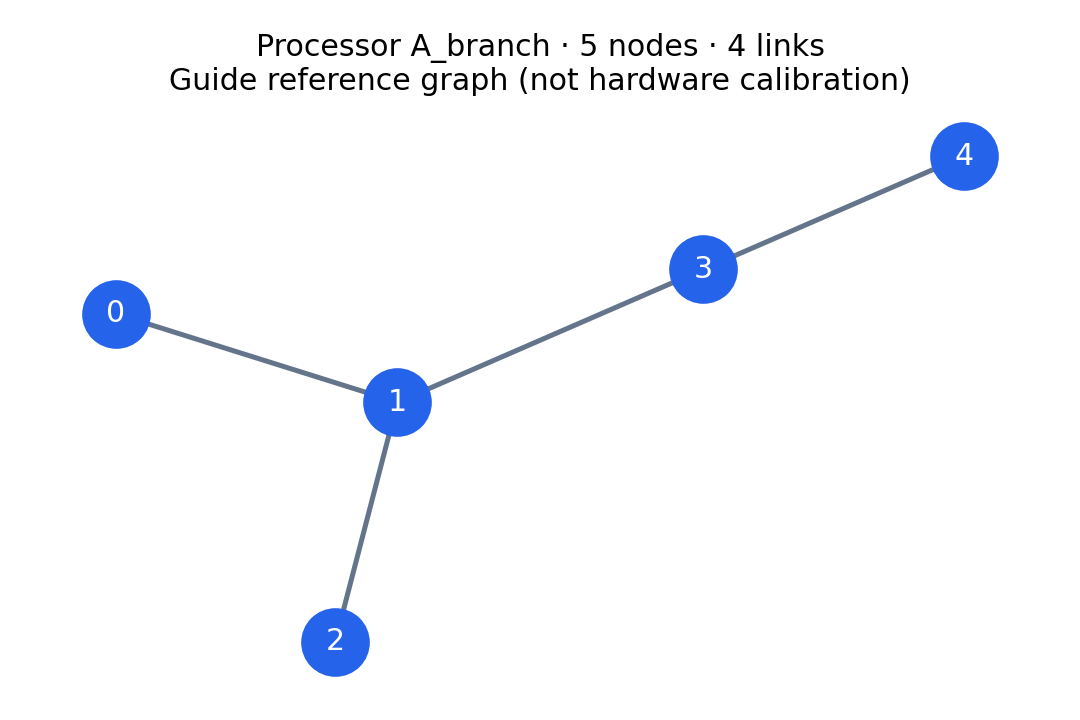

B_ref12_coupling.png


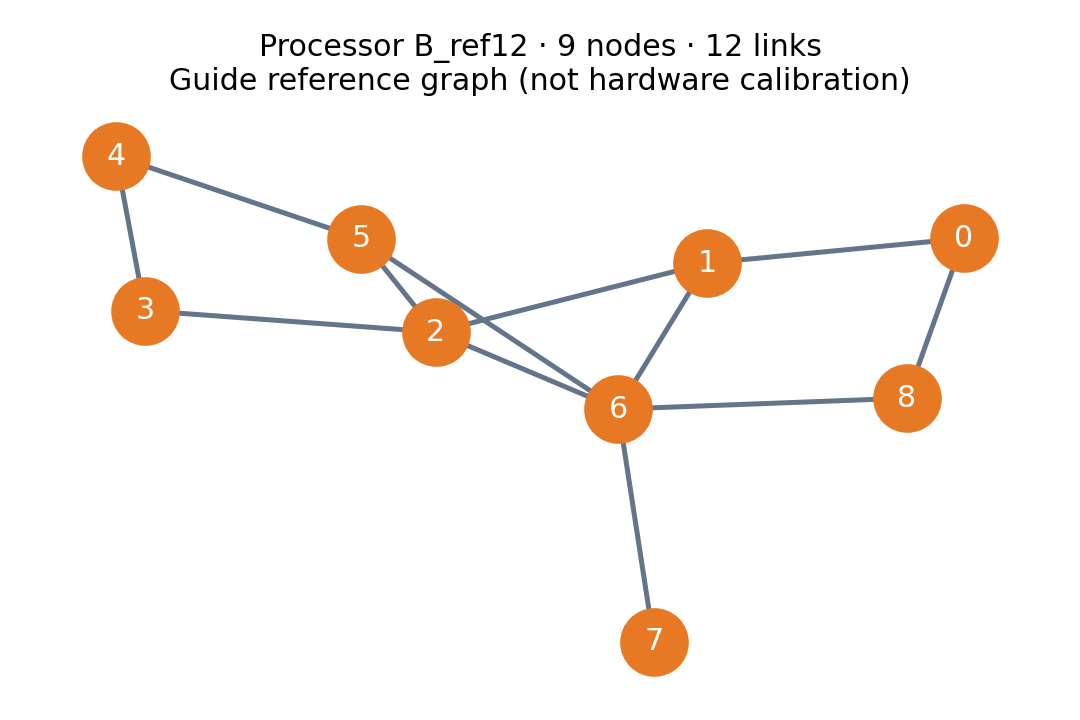

ideal_ab_resources.png


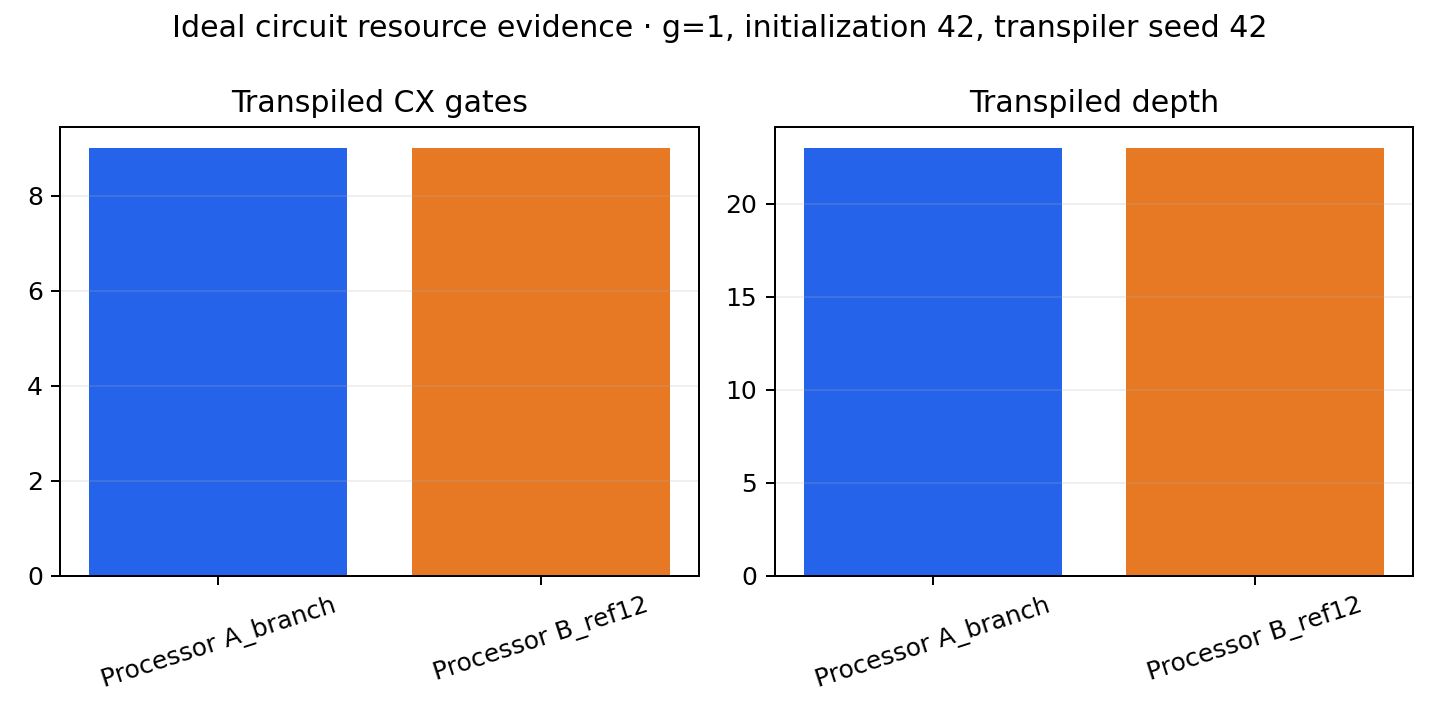

ideal_vqe_energy_error.png


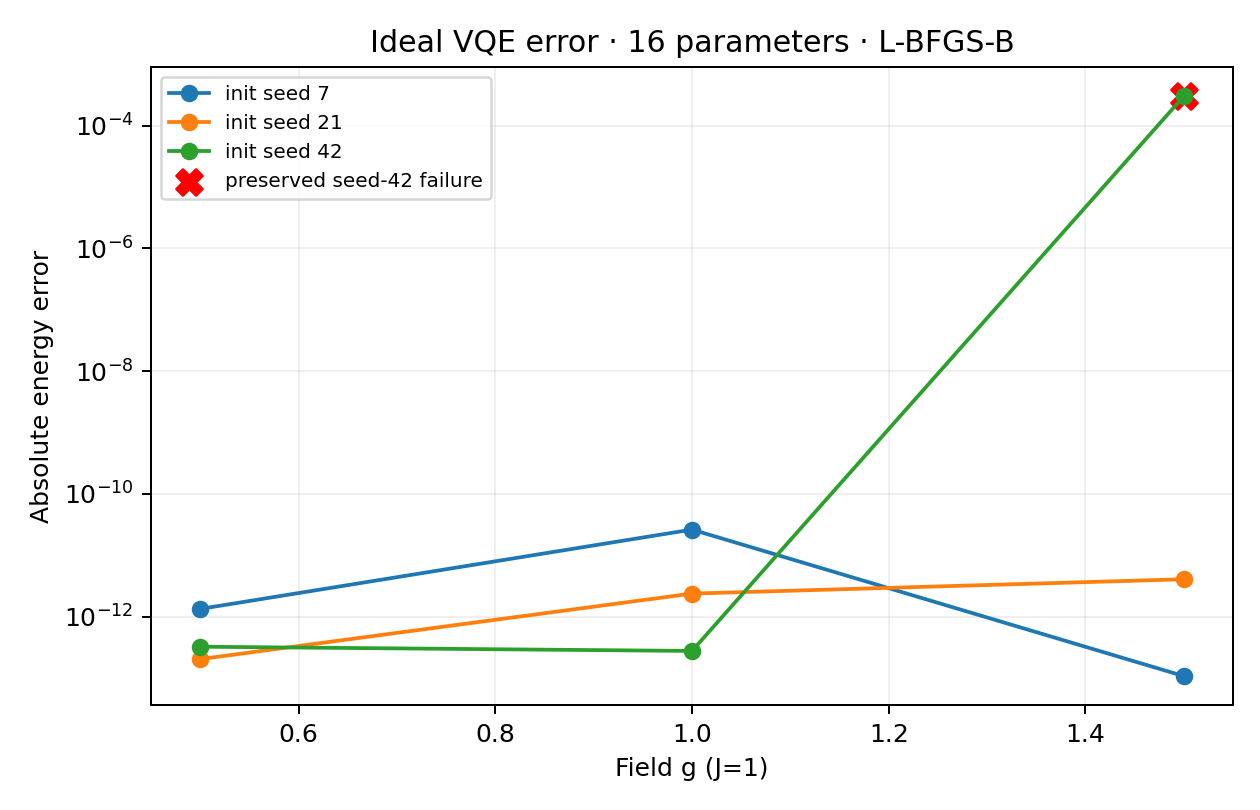

noisy_ab_energy.png


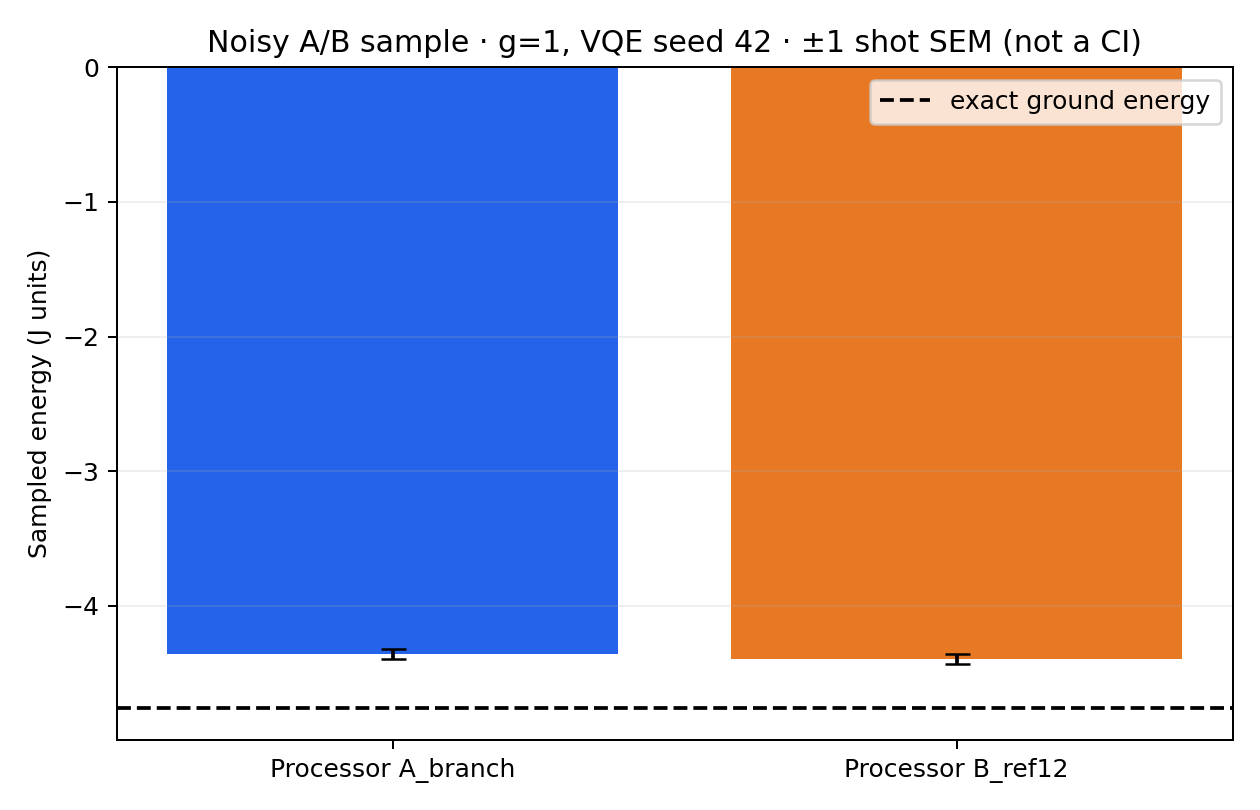

paired_noisy_energy_difference.png


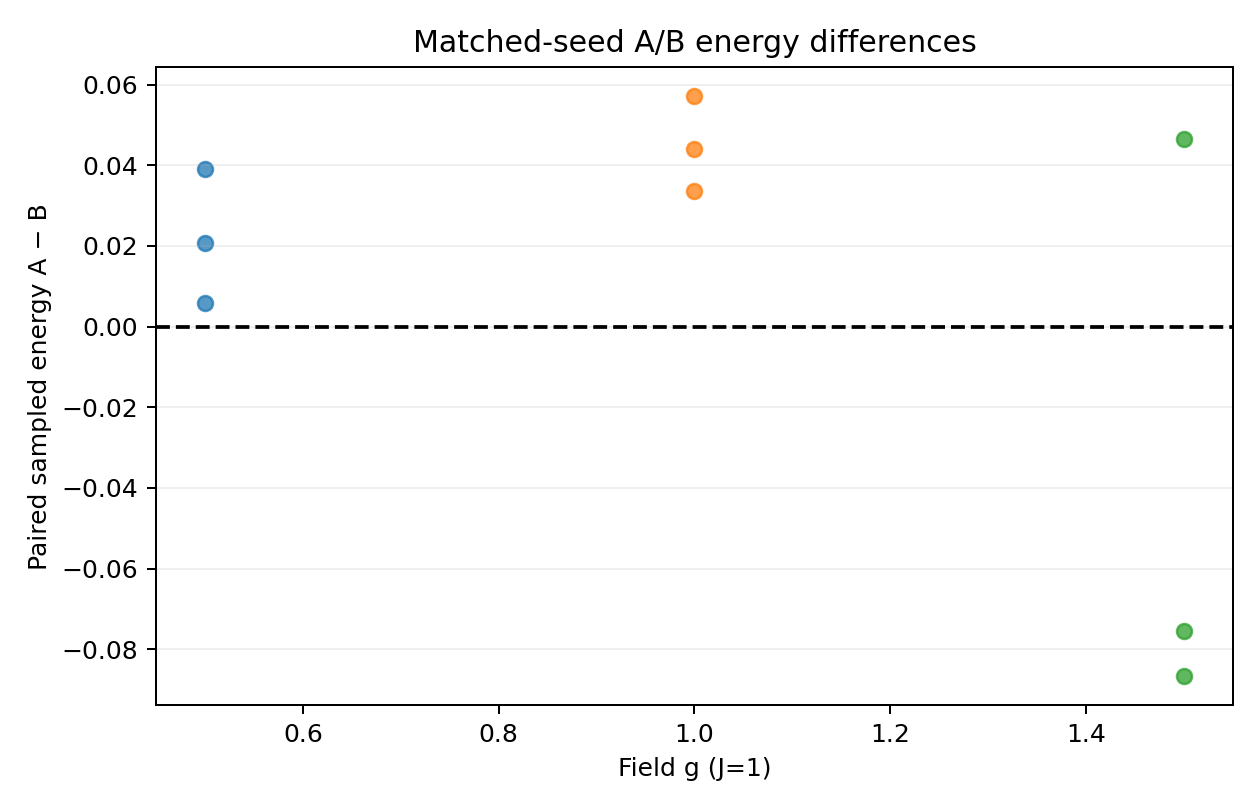

In [7]:
from IPython.display import Image, display
for path in sorted((ROOT / "results/figures").glob("*.png")):
    print(path.name)
    display(Image(filename=str(path)))

## Supplementary E4 ansatz-pattern experiment

E4 is a separate, pre-registered supplementary study on the same frozen A/B graphs. It is not used to modify the canonical maps or primary results. The default pipeline never runs E4.

,pattern,architecture,n_runs,optimizer_success_count,optimizer_failure_count,semantic_fidelity_min,ideal_absolute_error_mean,ideal_absolute_error_sample_sd,ideal_absolute_error_sem,compiled_cx_count_mean,...,noisy_absolute_error_sem,noisy_signed_error_mean,noisy_signed_error_sample_sd,noisy_signed_error_sem,noisy_shift_from_ideal_mean,noisy_shift_from_ideal_sample_sd,noisy_shift_from_ideal_sem,shot_sem_mean,shot_sem_sample_sd,shot_sem_sem
0,path,Processor A_branch,9,8,1,1.0,3.351123e-05,1.005337e-04,3.351123e-05,9,...,0.027919,0.369330,0.083757,0.027919,0.369297,0.083704,0.027901,0.035179,0.006749,0.002250
1,path,Processor B_ref12,9,8,1,1.0,3.351123e-05,1.005337e-04,3.351123e-05,9,...,0.033342,0.381917,0.100026,0.033342,0.381883,0.099984,0.033328,0.035281,0.006810,0.002270
2,ring,Processor A_branch,9,9,0,1.0,2.411404e-13,2.876840e-13,9.589465e-14,27,...,0.071869,0.813639,0.215606,0.071869,0.813639,0.215606,0.071869,0.040585,0.009278,0.003093
3,ring,Processor B_ref12,9,9,0,1.0,2.411404e-13,2.876840e-13,9.589465e-14,12,...,0.038430,0.528862,0.115290,0.038430,0.528862,0.115290,0.038430,0.037732,0.007839,0.002613
4,star,Processor A_branch,9,9,0,1.0,2.202655e-01,1.262882e-01,4.209607e-02,9,...,0.057803,0.622585,0.173408,0.057803,0.402320,0.048865,0.016288,0.033816,0.006243,0.002081
5,star,Processor B_ref12,9,9,0,1.0,2.202655e-01,1.262882e-01,4.209607e-02,9,...,0.055724,0.618462,0.167171,0.055724,0.398197,0.044644,0.014881,0.033893,0.006421,0.002140


,pattern,g,seed,architecture,optimizer_success,ideal_absolute_error,compiled_cx_count,compiled_depth,routing_swap_count,semantic_fidelity,noisy_energy,noisy_absolute_error,shot_sem
0,path,0.5,7,Processor A_branch,True,1.335820e-12,9,23,0,1.0,-3.155518,0.271517,0.026432
1,path,0.5,7,Processor B_ref12,True,1.335820e-12,9,23,0,1.0,-3.102295,0.324739,0.026798
2,path,0.5,21,Processor A_branch,True,2.033929e-13,9,23,0,1.0,-3.140381,0.286653,0.026530
3,path,0.5,21,Processor B_ref12,True,2.033929e-13,9,23,0,1.0,-3.134033,0.293001,0.026424
4,path,0.5,42,Processor A_branch,True,3.237410e-13,9,23,0,1.0,-3.101807,0.325227,0.026773
5,path,0.5,42,Processor B_ref12,True,3.237410e-13,9,23,0,1.0,-3.125977,0.301058,0.026958
6,path,1.0,7,Processor A_branch,True,2.622258e-11,9,23,0,1.0,-4.455078,0.303692,0.036875
7,path,1.0,7,Processor B_ref12,True,2.622258e-11,9,23,0,1.0,-4.342285,0.416485,0.037434
8,path,1.0,21,Processor A_branch,True,2.374989e-12,9,23,0,1.0,-4.408691,0.350079,0.037527
9,path,1.0,21,Processor B_ref12,True,2.374989e-12,9,23,0,1.0,-4.431152,0.327618,0.036820


E4_noisy_error_by_pattern.png


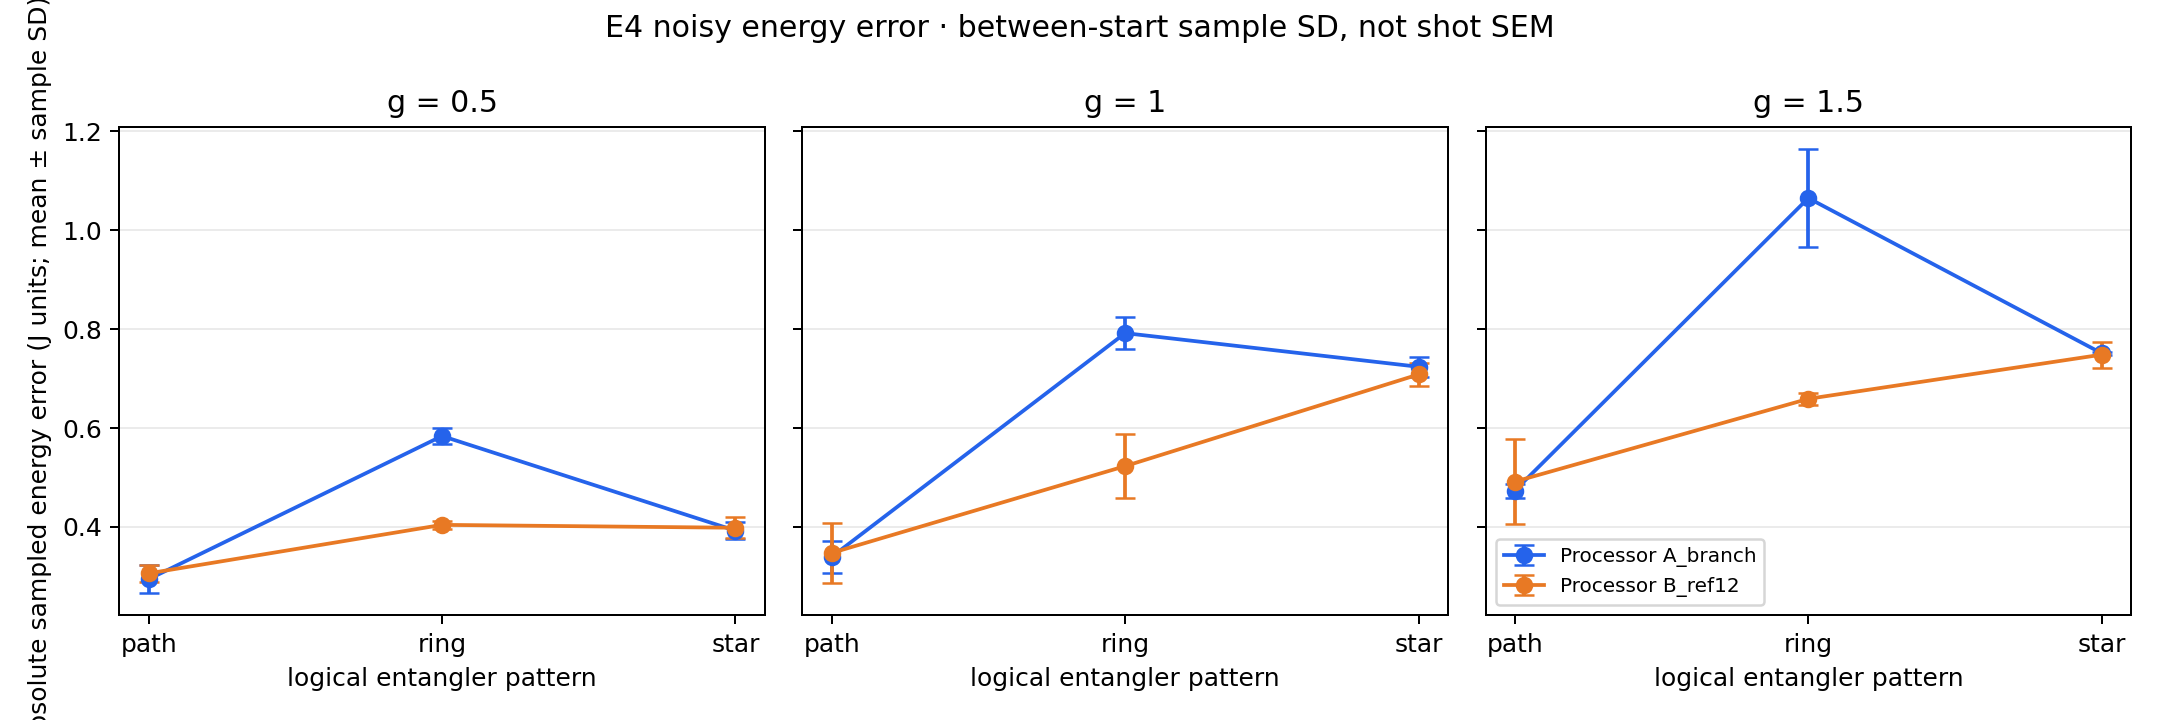

E4_resources_by_pattern.png


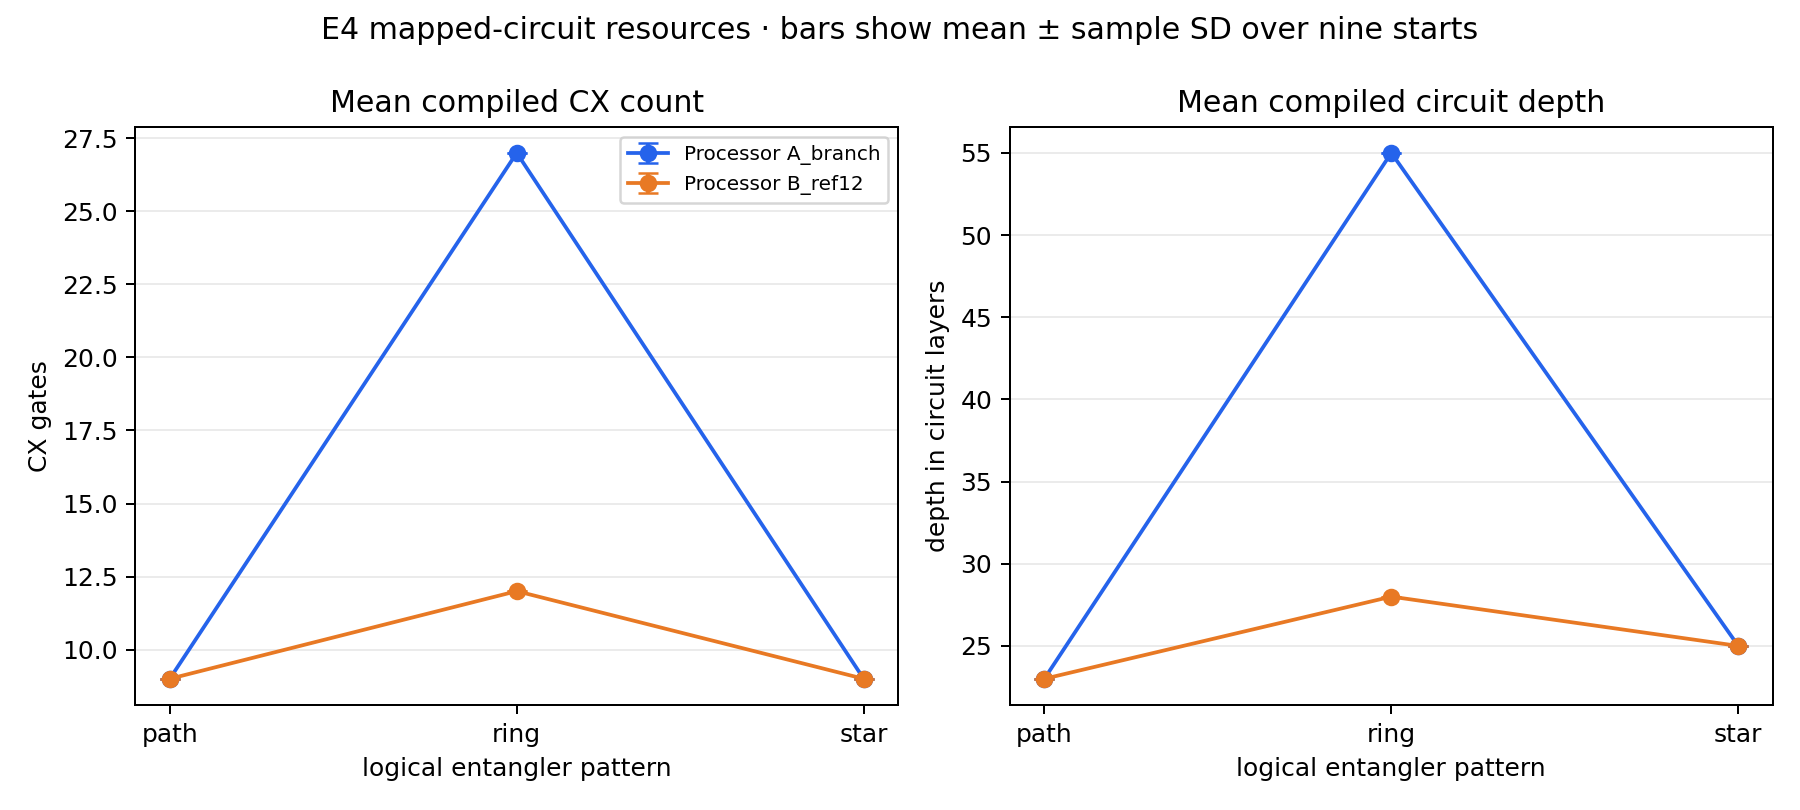

In [8]:
e4_summary_path = ROOT / "results/supplementary/tables/E4_pattern_summary.csv"
e4_path = ROOT / "results/supplementary/tables/E4_ansatz_patterns.csv"
if e4_path.is_file() and e4_summary_path.is_file():
    display(pd.read_csv(e4_summary_path))
    e4_runs = pd.read_csv(e4_path)
    display(e4_runs[["pattern", "g", "seed", "architecture", "optimizer_success", "ideal_absolute_error", "compiled_cx_count", "compiled_depth", "routing_swap_count", "semantic_fidelity", "noisy_energy", "noisy_absolute_error", "shot_sem"]])
    for path in sorted((ROOT / "results/supplementary/figures").glob("E4_*.png")):
        print(path.name)
        display(Image(filename=str(path)))
else:
    print("E4 outputs not present in this execution; the supplementary experiment has not been run here.")